# 02 · Momentum, mean reversion and trend following on S&P 500 sectors

**Question:** on the same 9 sector ETFs, with the same costs (5 bps) and the same monthly rebalancing, does any of three classic strategies beat holding the 9 sectors in equal parts?

**Short answer:** no, not in a way that can be told apart from luck. Trend following has the best Sharpe (0.80 against 0.64) and a much smaller drawdown (−17% against −54%), but the 95% interval of the Sharpe difference goes from about −0.14 to +0.45 (p ≈ 0.3). Momentum ties with the benchmark and mean reversion is slightly behind after costs. Three strategies are tested against the same benchmark, so this is a multiple comparison; the Holm-adjusted p-values are all above 0.9.

Rules of this notebook:
- It only imports from `backtester` and presents results; the logic lives in `src/` with its tests.
- The parameters of each strategy were fixed **before** looking at the results, and each strategy was run once. No variant was tried and discarded.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from backtester import ProportionalCosts, run_backtest
from backtester.data import load_prices
from backtester.metrics import drawdown, sharpe
from backtester.report import compare
from backtester.significance import (
    bootstrap_sharpe_difference,
    holm_adjust,
    ledoit_wolf_sharpe_test,
)
from backtester.strategies import CrossSectionalMomentum, MeanReversion, TrendFollowing
from backtester.strategy import EqualWeight

SECTOR_ETFS = ["XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY"]
START, END = "2005-01-01", "2026-10-31"  # fixed end date: reproducible numbers
COSTS_BPS = 5
BENCHMARK = "Equal weight"
IMG_DIR = Path("../docs/img")

## 1. Data

The same adjusted closes as in notebook 01 (9 SPDR sector ETFs, Yahoo Finance). The data checks and the limits of this universe (9 ETFs chosen with hindsight, one country, dividends reinvested without tax) are discussed there and apply here unchanged.

In [2]:
prices = load_prices(SECTOR_ETFS, start=START, end=END)
print(f"{prices.shape[0]} sessions, from {prices.index[0].date()} to {prices.index[-1].date()}")

5492 sessions, from 2005-01-03 to 2026-10-30


## 2. The four portfolios

| Portfolio | Rule at each month end | Type | Parameters |
|---|---|---|---|
| **12-1 momentum** | The 3 sectors with the highest return between *t-252* and *t-21*, in equal parts | Cross-sectional | lookback 252, skip 21, top 3 |
| **Mean reversion** | The 3 sectors with the lowest z-score of the price against its 20-day average, in equal parts | Cross-sectional | lookback 20, top 3, long-only |
| **Trend following** | Each sector gets 1/9 if its price is above its own 200-day average; otherwise that 1/9 stays in cash | Time-series | window 200 |
| **Equal weight** | The 9 sectors at 1/9 each | Benchmark | |

All four pay 5 bps per unit of turnover and trade only at month end; in between, the weights drift.

Three things to keep in mind when reading the results:

- **A common period.** Momentum needs a year of history, so everything is compared from its first invested day (February 2006). Otherwise the comparison would mix the strategies with a year in cash.
- **Monthly rebalancing does not suit mean reversion.** A 20-day z-score is a signal that should decay in days, and here it is read once a month and held for a month. What is tested is "buy the sectors that are most below their recent average at month end", which is closer to the one-month reversal of Jegadeesh (1990) than to a daily reversal strategy. The frequency was fixed in advance to make the four portfolios comparable.
- **Cash earns nothing.** The engine pays 0% on cash and the Sharpe uses a risk-free rate of 0. Trend following keeps about a quarter of the portfolio in cash on average, so its return is somewhat understated in the years with positive rates.

In [3]:
strategies = {
    "12-1 momentum": CrossSectionalMomentum(top_n=3),
    "Mean reversion": MeanReversion(lookback=20, top_n=3),
    "Trend following": TrendFollowing(window=200),
    BENCHMARK: EqualWeight(),
}
costs = ProportionalCosts(bps=COSTS_BPS)
full = {name: run_backtest(prices, s, costs, rebalance="ME") for name, s in strategies.items()}

start = max(result.first_active for result in full.values())
results = {name: result.since(start) for name, result in full.items()}
challengers = [name for name in results if name != BENCHMARK]
print(f"Period compared: {start.date()} to {prices.index[-1].date()}")

Period compared: 2006-02-01 to 2026-10-30


## 3. Equity and drawdown

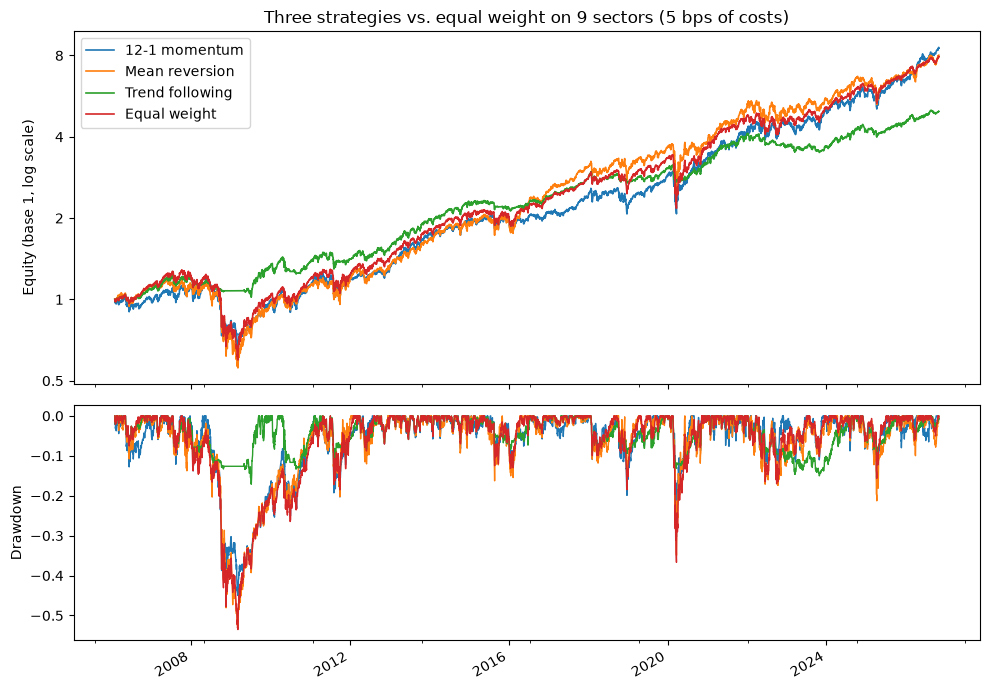

In [4]:
equity = pd.DataFrame({name: result.equity for name, result in results.items()})
drawdowns = pd.DataFrame({name: drawdown(result.returns) for name, result in results.items()})

fig, (ax_equity, ax_drawdown) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]}
)
equity.plot(ax=ax_equity, lw=1.2)
ax_equity.set_yscale("log")  # 20 years of compounding: on a linear scale 2008 is invisible
ax_equity.set_yticks([0.5, 1, 2, 4, 8], labels=["0.5", "1", "2", "4", "8"])
ax_equity.minorticks_off()
ax_equity.set_ylabel("Equity (base 1, log scale)")
ax_equity.set_title(f"Three strategies vs. equal weight on 9 sectors ({COSTS_BPS} bps of costs)")
drawdowns.plot(ax=ax_drawdown, lw=1, legend=False)
ax_drawdown.set_ylabel("Drawdown")
ax_drawdown.set_xlabel("")
fig.tight_layout()
IMG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(IMG_DIR / "strategies_comparison.png", dpi=150)
plt.show()

## 4. Metrics

In [5]:
compare(results).round(3)

,12-1 momentum,Mean reversion,Trend following,Equal weight
CAGR,0.109,0.106,0.080,0.105
Annual volatility,0.188,0.200,0.104,0.183
Sharpe,0.645,0.603,0.798,0.637
Sortino,0.907,0.860,1.103,0.892
Max drawdown,-0.450,-0.530,-0.171,-0.535
Calmar,0.242,0.199,0.471,0.196
Annual turnover,5.250,15.734,1.871,0.294
Annual costs,0.003,0.008,0.001,0.000


Three more figures that explain the table: the Sharpe before costs, the average share of the portfolio that is invested, and the daily correlation with the benchmark.

In [6]:
benchmark = results[BENCHMARK]
pd.DataFrame(
    {
        "Sharpe before costs": {name: sharpe(r.gross_returns) for name, r in results.items()},
        "Sharpe after costs": {name: sharpe(r.returns) for name, r in results.items()},
        "Average exposure": {name: r.weights.sum(axis=1).mean() for name, r in results.items()},
        "Correlation with equal weight": {
            name: r.returns.corr(benchmark.returns) for name, r in results.items()
        },
    }
).round(3)

,Sharpe before costs,Sharpe after costs,Average exposure,Correlation with equal weight
12-1 momentum,0.659,0.645,1.000,0.900
Mean reversion,0.642,0.603,1.000,0.928
Trend following,0.807,0.798,0.748,0.722
Equal weight,0.638,0.637,1.000,1.000


## 5. Year by year

Annual return of each portfolio. 2006 starts in February and 2026 ends in October.

In [7]:
by_year = pd.DataFrame(
    {name: (1 + r.returns).groupby(r.returns.index.year).prod() - 1 for name, r in results.items()}
)
wins = by_year[challengers].gt(by_year[BENCHMARK], axis=0).sum()
print(f"Years (of {len(by_year)}) in which each strategy beats equal weight:")
print(wins.to_string())
by_year.round(3)

Years (of 21) in which each strategy beats equal weight:
12-1 momentum      10
Mean reversion     10
Trend following     4


,12-1 momentum,Mean reversion,Trend following,Equal weight
Date,,,,
2006,0.004,0.127,0.090,0.125
2007,0.113,0.002,0.106,0.095
2008,-0.269,-0.338,-0.107,-0.355
2009,0.195,0.262,0.221,0.281
2010,0.150,0.178,0.042,0.161
2011,0.064,0.044,0.026,0.031
2012,0.073,0.127,0.090,0.147
2013,0.372,0.284,0.299,0.308
2014,0.107,0.128,0.143,0.133


A diagnostic, not a new test: the Sharpe of each portfolio with the year 2008 removed. It shows how much of each result depends on that single year.

In [8]:
pd.DataFrame(
    {
        "Sharpe, full period": {name: sharpe(r.returns) for name, r in results.items()},
        "Sharpe without 2008": {
            name: sharpe(r.returns[r.returns.index.year != 2008]) for name, r in results.items()
        },
    }
).round(3)

,"Sharpe, full period",Sharpe without 2008
12-1 momentum,0.645,0.803
Mean reversion,0.603,0.777
Trend following,0.798,0.882
Equal weight,0.637,0.845


## 6. Is any difference significant?

For each strategy the question is the same as in notebook 01: could the observed Sharpe difference against equal weight be luck? The same two tests are used, both on the **paired** daily returns:

- **Stationary bootstrap** (Politis and Romano, 1994), resampling both series with the same random blocks. The block length is chosen automatically for each pair.
- **Ledoit-Wolf (2008)** asymptotic test with a HAC standard error.

**This is a multiple comparison.** Three strategies are tested against the same benchmark. If none had any edge and each test were run at 5%, the chance of at least one "significant" result would be up to about 14% (1 − 0.95³), not 5%. Picking the best of the three and reporting only its p-value would be the same mistake in a less visible form. So the table shows the raw p-values and, next to them, the p-values adjusted with the **Holm (1979)** step-down method, which controls the probability of at least one false positive among the three and needs no assumption about how the tests depend on each other (they are strongly dependent here: same benchmark, same assets).

In [9]:
rows = {}
for name in challengers:
    boot = bootstrap_sharpe_difference(
        results[name].returns, benchmark.returns, n_boot=10_000, seed=0
    )
    hac = ledoit_wolf_sharpe_test(results[name].returns, benchmark.returns)
    rows[name] = {
        "Sharpe difference": boot.estimate,
        "Bootstrap 95% CI low": boot.ci_low,
        "Bootstrap 95% CI high": boot.ci_high,
        "Bootstrap p": boot.p_value,
        "Ledoit-Wolf 95% CI low": hac.ci_low,
        "Ledoit-Wolf 95% CI high": hac.ci_high,
        "Ledoit-Wolf p": hac.p_value,
        "Mean block (days)": round(boot.block_length),
    }
tests = pd.DataFrame(rows).T
tests.insert(4, "Bootstrap p (Holm)", holm_adjust(tests["Bootstrap p"]))
tests.insert(8, "Ledoit-Wolf p (Holm)", holm_adjust(tests["Ledoit-Wolf p"]))
tests.round(3)

,Sharpe difference,Bootstrap 95% CI low,Bootstrap 95% CI high,Bootstrap p,Bootstrap p (Holm),Ledoit-Wolf 95% CI low,Ledoit-Wolf 95% CI high,Ledoit-Wolf p,Ledoit-Wolf p (Holm),Mean block (days)
12-1 momentum,0.008,-0.167,0.136,0.917,1.000,-0.170,0.186,0.933,1.00,123.0
Mean reversion,-0.034,-0.169,0.079,0.573,1.000,-0.178,0.110,0.644,1.00,130.0
Trend following,0.161,-0.143,0.453,0.319,0.958,-0.148,0.469,0.307,0.92,123.0


**Reading the result**

- **No strategy is distinguishable from equal weight.** Zero is inside every 95% interval, with both methods. The raw p-values are 0.92 (momentum), 0.57 (mean reversion) and 0.32 (trend following) with the bootstrap, and 0.93, 0.64 and 0.31 with Ledoit-Wolf. The two methods reach the conclusion by different routes and agree.
- **After the Holm correction** the smallest p-value goes from 0.32 to 0.96 (bootstrap) and from 0.31 to 0.92 (Ledoit-Wolf); the other two become 1. Here the correction does not change the conclusion, because nothing was significant before it. It would have mattered in the opposite case: a raw p-value of 0.03 for the best of three strategies becomes 0.09 after Holm and should not be reported as a finding.
- **The intervals are wide.** For trend following the difference is 0.16 and the interval runs from about −0.14 to +0.45. That is compatible with no edge, and also with a large one. "Not significant" here means "21 years are not enough to tell", not "shown to be useless".
- **The real number of trials is larger than three.** The Holm correction only covers the three tests in this table. It does not cover the choices made before them: the universe, the lookbacks (252, 20, 200), top 3, monthly rebalancing, and the fact that these three are the textbook strategies precisely because they worked in past samples. Those parameters were fixed in advance and not tuned, which limits the damage, but as more variants are added to this project the correct tool is the Deflated Sharpe Ratio (applied in notebook 04).

## 7. Interpretation

**None of the three strategies beats equal weight in a way that can be told apart from luck.**

| | 12-1 momentum | Mean reversion | Trend following | Equal weight |
|---|---|---|---|---|
| CAGR | 10.9% | 10.6% | 8.0% | 10.5% |
| Annual volatility | 18.8% | 20.0% | 10.4% | 18.3% |
| Sharpe | 0.64 | 0.60 | 0.80 | 0.64 |
| Max drawdown | −45.0% | −53.0% | −17.1% | −53.5% |
| Annual turnover | 5.2 | 15.7 | 1.9 | 0.3 |
| Sharpe difference vs. equal weight | +0.01 | −0.03 | +0.16 | |
| Bootstrap p-value (raw / Holm) | 0.92 / 1.00 | 0.57 / 1.00 | 0.32 / 0.96 | |

- **Trend following is a different portfolio, not a better one.** It is 75% invested on average, so it earns less (8.0% against 10.5% a year) with much less risk (volatility 10.4% against 18.3%, max drawdown −17% against −54%). The higher Sharpe comes from the lower risk, not from a higher return. It beats equal weight in only 4 of 21 years (2007, 2008, 2014 and 2018), and one of them carries the result: in 2008 it lost 10.7% while equal weight lost 35.5%. With 2008 removed, the Sharpe ratios are 0.88 and 0.84 and the gap almost disappears. In the other two bad years of the sample it did not help: in 2020 the fall was too fast for a 200-day average read once a month (+5.3% against +10.1%), and in 2022 it lost more than the benchmark (−9.4% against −5.2%). The drawdown protection is real in this sample, but it rests on one slow bear market.
- **Mean reversion is equal weight with more costs.** Its daily correlation with the benchmark is 0.93. Before costs its Sharpe is 0.64, the same as equal weight; it turns the portfolio over almost 16 times a year, which costs 0.8% a year at 5 bps and leaves the Sharpe at 0.60. There is no sign of reversal between sectors at this frequency. This says little about short-term reversal itself, which is a daily-to-weekly effect in individual stocks: the monthly rebalancing and the 9 diversified ETFs are a poor setting for it.
- **Momentum** repeats the result of notebook 01: a tie (Sharpe 0.64 against 0.64).

**Limitations**

- Three tests against the same benchmark, plus the untested choices listed in section 6. The p-values above are optimistic if read one by one.
- One sample of 21 years with three crises. The statistical tests measure the noise of daily returns, but the conclusion about trend following depends on how many slow bear markets the sample contains, and that number is one.
- Cash earns 0% and the risk-free rate is 0. With a real cash rate, trend following's return would be somewhat higher and every Sharpe somewhat lower.
- Each strategy uses a single parameter set. Nothing here says how the results change with the lookback, the window or `top_n`; that is the parameter sensitivity analysis of notebook 04.
- The universe is 9 US sector ETFs selected because they exist today.

**Next steps**

- Volatility targeting: trend following's advantage is lower risk, so the fair comparison is against equal weight scaled to the same volatility. Not done in v1.0; listed in the roadmap's [Future work](../docs/ROADMAP.md#future-work).
- Mean reversion with weekly or daily rebalancing and more realistic costs, declared as a new test and counted as such. Realistic costs are listed in the roadmap's [Future work](../docs/ROADMAP.md#future-work); a faster rebalancing is not on the roadmap.
- Deflated Sharpe Ratio to account for the number of strategies and variants tried across the project. Done in [notebook 04](04_robustness.ipynb).